In [1]:
import os
import pandas as pd
import numpy as np
import joblib
from dotenv import load_dotenv

load_dotenv()
gex_x_calibration_path = os.getenv("GEX_X_CAL_PATH")
gex_y_calibration_path = os.getenv("GEX_Y_CAL_PATH")
gex_x_test_path = os.getenv("GEX_X_TEST_PATH")
gex_y_test_path = os.getenv("GEX_Y_TEST_PATH")
gex_rf_model_path = os.getenv("GEX_RF_MODEL_PATH")
gex_selected_features_path = os.getenv("GEX_SELECTED_FEATURES_PATH")
output_dir = os.getenv("OUTPUT_DIR")

# Print configuration
print(f"gex_x_calibration_path: {gex_x_calibration_path}")
print(f"gex_y_calibration_path: {gex_y_calibration_path}")
print(f"gex_x_test_path: {gex_x_test_path}")
print(f"gex_y_test_path: {gex_y_test_path}")
print(f"gex_rf_model_path: {gex_rf_model_path}")
print(f"gex_selected_features_path: {gex_selected_features_path}")
print(f"output_dir: {output_dir}")


gex_x_calibration_path: /home/mariya/Data/pallas/nf-core-gexml-output-cal/transpose/transposed.csv
gex_y_calibration_path: /home/mariya/Data/pallas/nf-core-gexml-output-cal/class/subtypes.tsv
gex_x_test_path: /home/mariya/Data/pallas/nf-core-gexml-output-test/transpose/transposed.csv
gex_y_test_path: /home/mariya/Data/pallas/nf-core-gexml-output-test/class/subtypes.tsv
gex_rf_model_path: /home/mariya/Data/pallas/training/final_model.pkl
gex_selected_features_path: /home/mariya/Data/pallas/training/selected_features.pkl
output_dir: /home/mariya/Data/pallas/reports


In [2]:
# Read in both sets of X and y
gex_x_calibration = pd.read_csv(gex_x_calibration_path, index_col=0)
gex_y_calibration = pd.read_csv(gex_y_calibration_path, sep="\t", index_col=0)
gex_x_test = pd.read_csv(gex_x_test_path, index_col=0)
gex_y_test = pd.read_csv(gex_y_test_path, sep="\t", index_col=0)

In [3]:
y_cal = gex_y_calibration["class"]
y_test = gex_y_test["class"]
y_cal, y_test

(sample
 GE8322               B-ALL, ETV6::RUNX1
 ALLT-346                 B-ALL, KMT2A-r
 ALLT-338             B-ALL, ETV6::RUNX1
 GE0310               B-ALL, ETV6::RUNX1
 ALLT-371       B-ALL, high hyperdiploid
                          ...           
 SJHBBBM5TXY          B-ALL, ETV6::RUNX1
 SJHBBBM4JQZ          B-ALL, ETV6::RUNX1
 SJHBBBN9RDM    B-ALL, high hyperdiploid
 SJHBBBM588V    B-ALL, high hyperdiploid
 SJHBBBM67H6    B-ALL, high hyperdiploid
 Name: class, Length: 486, dtype: object,
 sample
 ALL_268               B-ALL, PAX5alt
 ALL_1154              B-ALL, PAX5alt
 ALL_254                        T-ALL
 ALL_180               B-ALL, KMT2A-r
 ALL_210     B-ALL, high hyperdiploid
                       ...           
 ALLT-343            B-ALL, BCR::ABL1
 ALLT-373                       T-ALL
 GE8329            B-ALL, ETV6::RUNX1
 ALLT-363          B-ALL, ETV6::RUNX1
 GE3317            B-ALL, ETV6::RUNX1
 Name: class, Length: 464, dtype: object)

In [4]:
# Align indices of X and y
gex_x_calibration = gex_x_calibration.loc[y_cal.index]
gex_x_test = gex_x_test.loc[y_test.index]
gex_x_calibration.shape, gex_x_test.shape

((486, 19916), (464, 19916))

In [5]:
# Get selected features
selected_features = joblib.load(gex_selected_features_path)
gex_x_calibration = gex_x_calibration[selected_features]
gex_x_test = gex_x_test[selected_features]
gex_x_calibration.shape, gex_x_test.shape

((486, 3934), (464, 3934))

In [6]:
# Get predictions on calibration and test sets
rf_model = joblib.load(gex_rf_model_path)
y_cal_pred = rf_model.predict(gex_x_calibration)
y_test_pred = rf_model.predict(gex_x_test)
y_cal_pred, y_cal

(array(['B-ALL, ETV6::RUNX1', 'B-ALL, KMT2A-r', 'B-ALL, ETV6::RUNX1',
        'B-ALL, ETV6::RUNX1', 'B-ALL, high hyperdiploid',
        'B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1',
        'B-ALL, high hyperdiploid', 'B-ALL, high hyperdiploid',
        'B-ALL, ETV6::RUNX1', 'B-ALL, high hyperdiploid',
        'B-ALL, TCF3::PBX1', 'B-ALL, high hyperdiploid',
        'B-ALL, high hyperdiploid', 'B-ALL, NUTM1-r', 'B-ALL, PAX5 P80R',
        'B-ALL, PAX5alt', 'B-ALL, ETV6::RUNX1', 'B-ALL, ZNF384-r',
        'B-ALL, ETV6::RUNX1', 'B-ALL, DUX4-r', 'B-ALL, BCR::ABL1-like',
        'B-ALL, MYC-r', 'B-ALL, high hyperdiploid', 'B-ALL, KMT2A-r',
        'B-ALL, KMT2A-r', 'B-ALL, ETV6::RUNX1', 'B-ALL, iAMP21',
        'B-ALL, IKZF1 N159Y', 'B-ALL, ETV6::RUNX1', 'B-ALL, BCR::ABL1',
        'B-ALL, BCR::ABL1-like', 'B-ALL, BCR::ABL1',
        'B-ALL, BCR::ABL1-like', 'B-ALL, KMT2A-r', 'B-ALL, PAX5alt',
        'B-ALL, PAX5alt', 'B-ALL, KMT2A-r', 'B-ALL, ETV6::RUNX1',
        'B-ALL, ETV6::RUNX1', 'B-

In [7]:
# Get probas
y_cal_proba = rf_model.predict_proba(gex_x_calibration)
y_test_proba = rf_model.predict_proba(gex_x_test)
y_cal_proba, y_test_proba

(array([[0.00529633, 0.00761584, 0.00179122, ..., 0.01916299, 0.00184088,
         0.00920205],
        [0.00772007, 0.00449424, 0.01857663, ..., 0.01098581, 0.0290885 ,
         0.09179849],
        [0.        , 0.        , 0.        , ..., 0.00970826, 0.        ,
         0.00507819],
        ...,
        [0.        , 0.        , 0.00077568, ..., 0.08695028, 0.00385996,
         0.00478943],
        [0.00383355, 0.00197642, 0.002     , ..., 0.12992871, 0.00388833,
         0.00832057],
        [0.00194815, 0.        , 0.        , ..., 0.15074601, 0.00564033,
         0.00442803]], shape=(486, 28)),
 array([[0.00198444, 0.00123264, 0.00057348, ..., 0.02315372, 0.00188034,
         0.00504983],
        [0.0017049 , 0.00196474, 0.00246171, ..., 0.0261456 , 0.002     ,
         0.00838735],
        [0.02580101, 0.01246379, 0.01439018, ..., 0.00449325, 0.01983142,
         0.37979732],
        ...,
        [0.        , 0.0039337 , 0.00120122, ..., 0.02827221, 0.0018577 ,
         0.004922

=== Classifier-level metrics ===
accuracy       0.927984
macro_f1       0.921648
micro_f1       0.927984
weighted_f1    0.924801
mcc            0.921155
cohen_kappa    0.920858
log_loss       0.707762
brier          0.010050
macro_auroc    0.996857
macro_auprc    0.955979
dtype: float64

=== Per-class metrics ===
                          precision    recall  f1-score     support     auroc  \
AML, APL-PML::RARA         1.000000  1.000000  1.000000    1.000000  1.000000   
AML, CBFA2T3::GLIS2        1.000000  1.000000  1.000000    1.000000  1.000000   
AML, CBFB::MYH11           1.000000  1.000000  1.000000   10.000000  1.000000   
AML, CEBPAalt              1.000000  0.666667  0.800000    3.000000  0.999310   
AML, KMT2A-r               1.000000  0.937500  0.967742   16.000000  0.999335   
AML, NPM1alt               0.800000  1.000000  0.888889    4.000000  0.997925   
AML, NUP98-r               1.000000  1.000000  1.000000    3.000000  1.000000   
AML, RUNX1::RUNX1T1        1.000000  

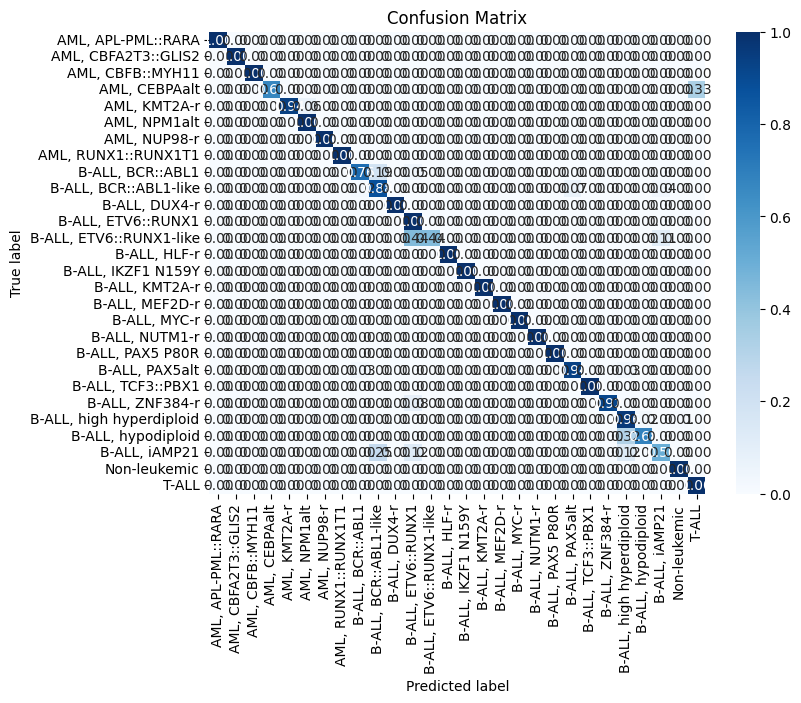

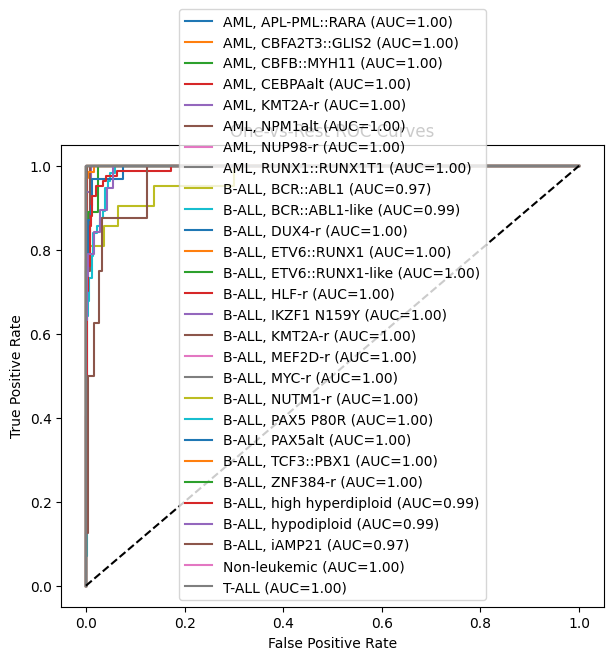

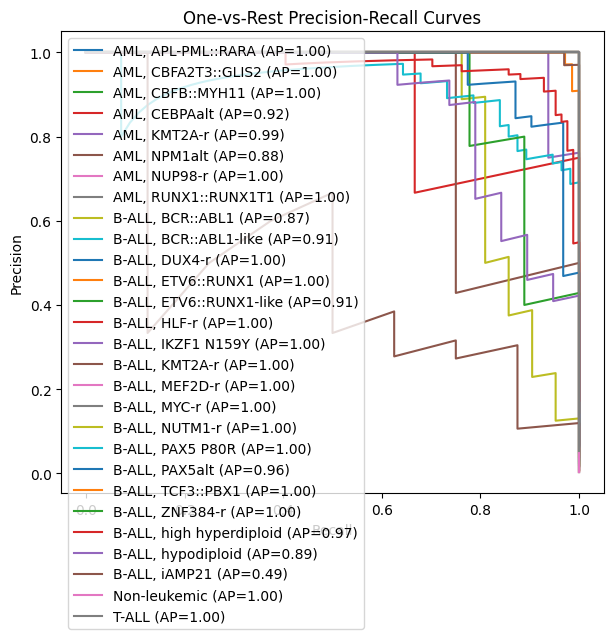

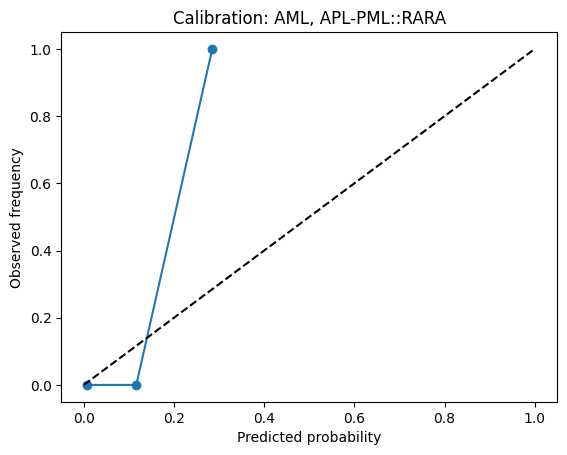

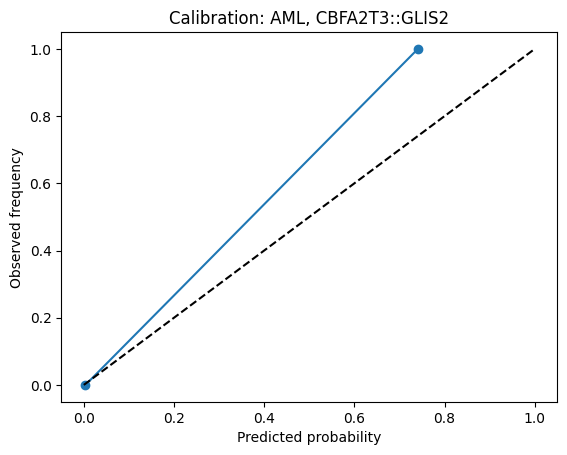

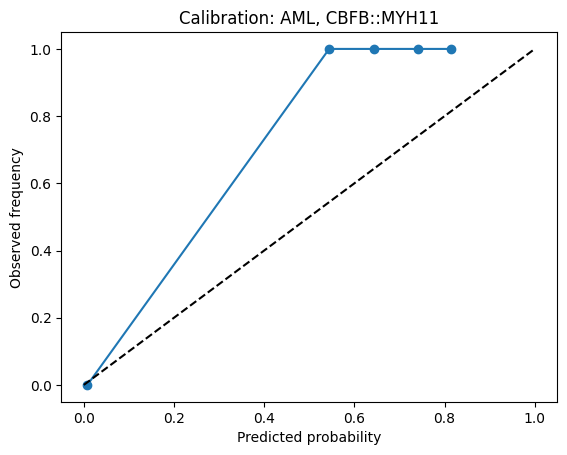

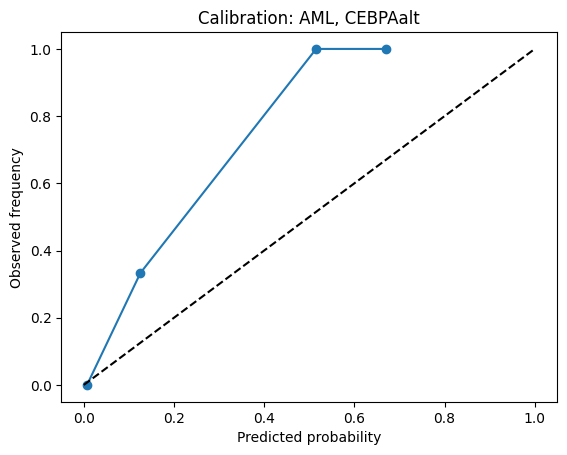

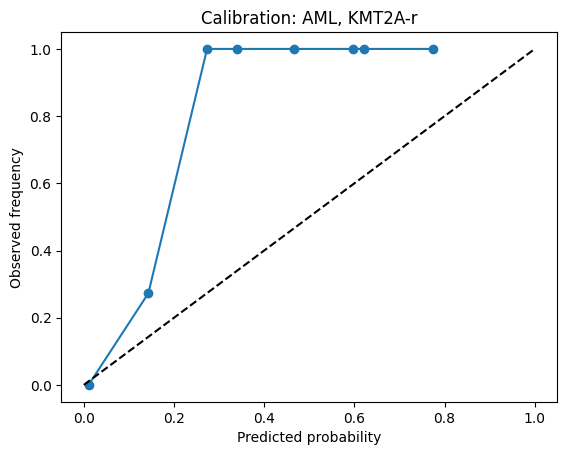

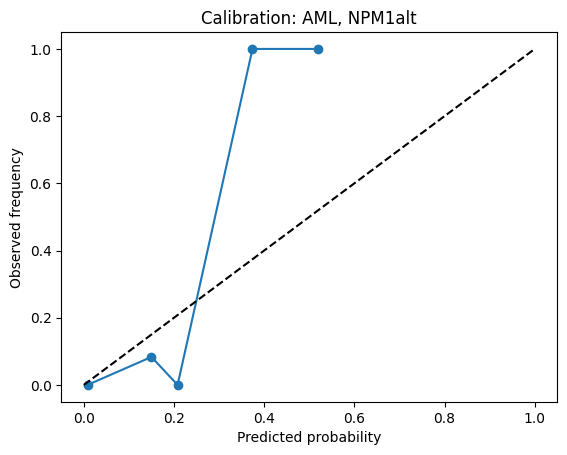

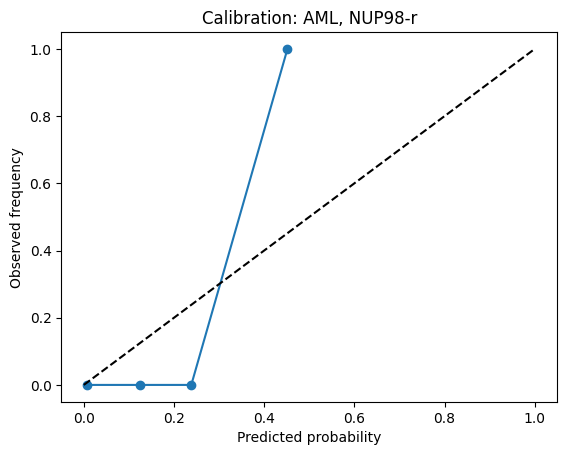

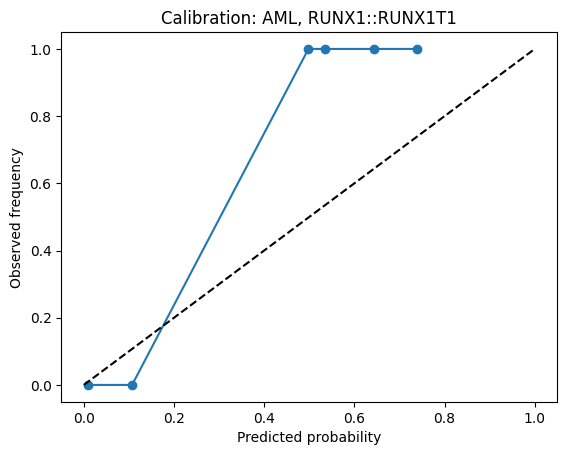

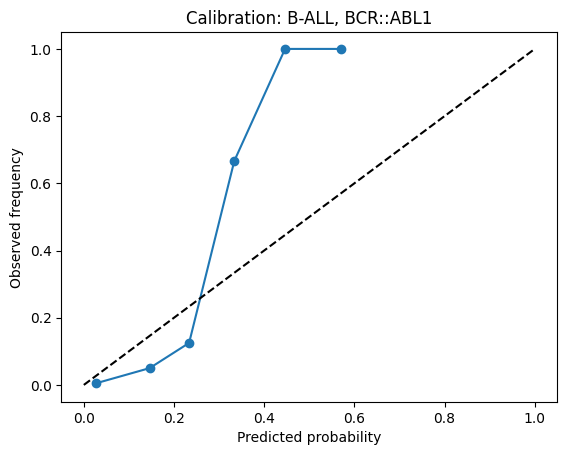

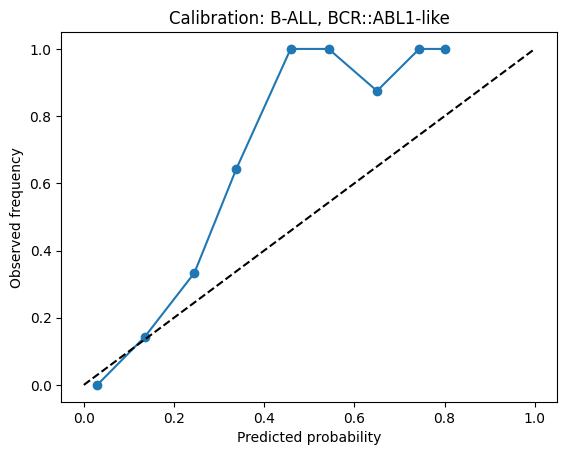

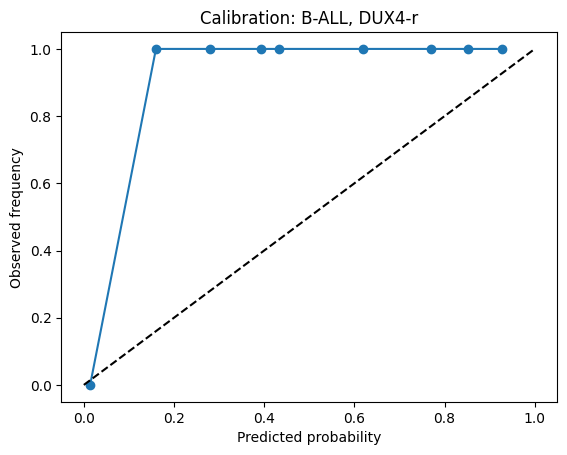

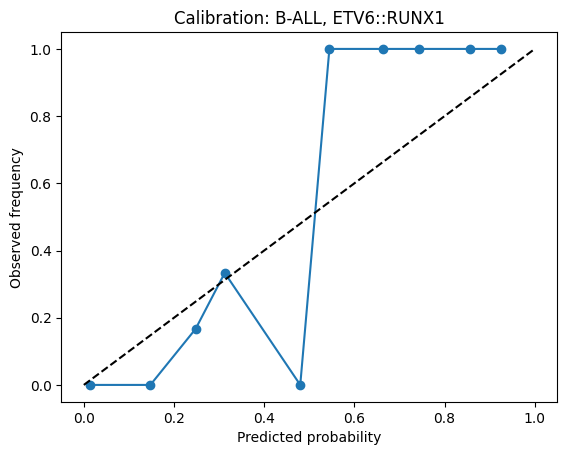

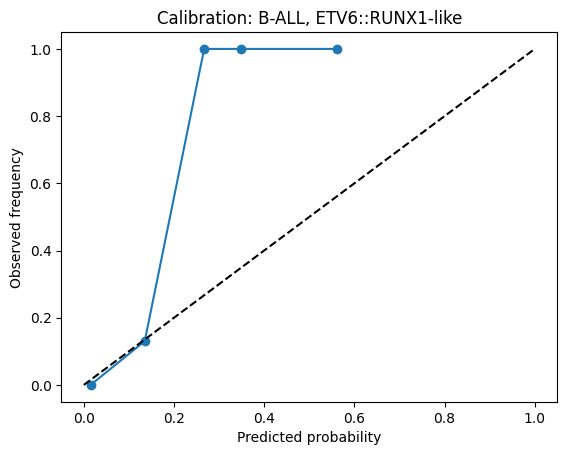

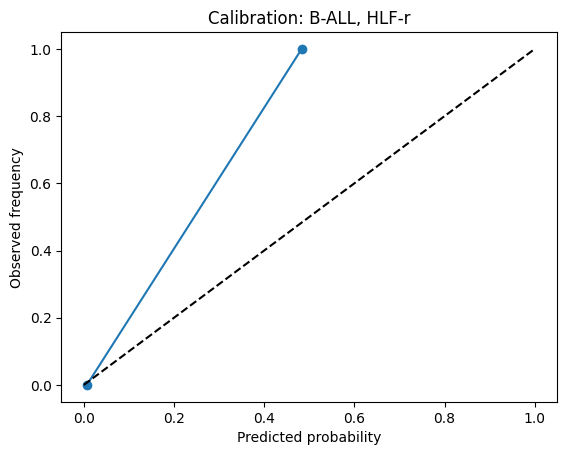

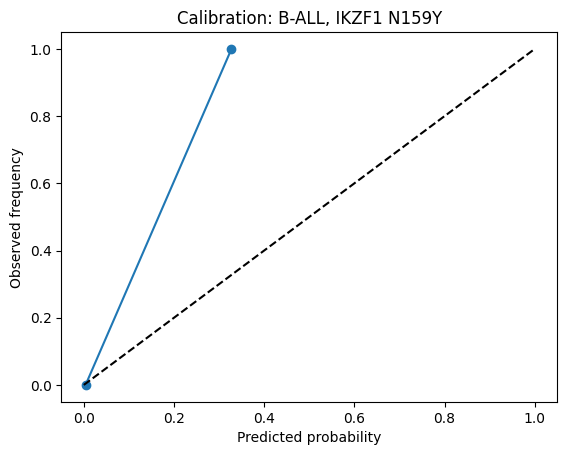

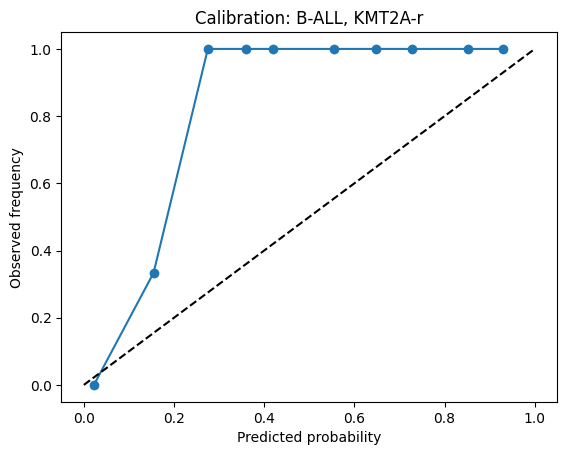

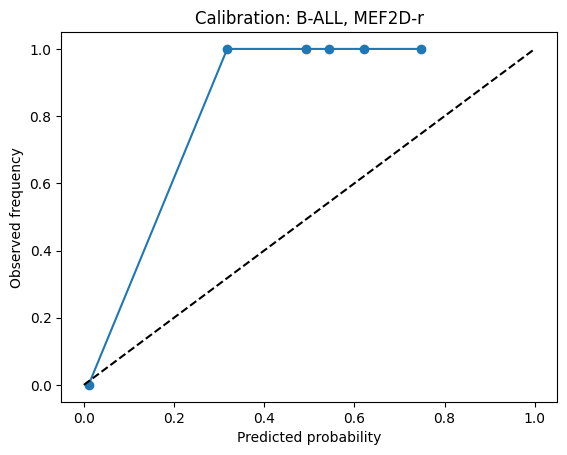

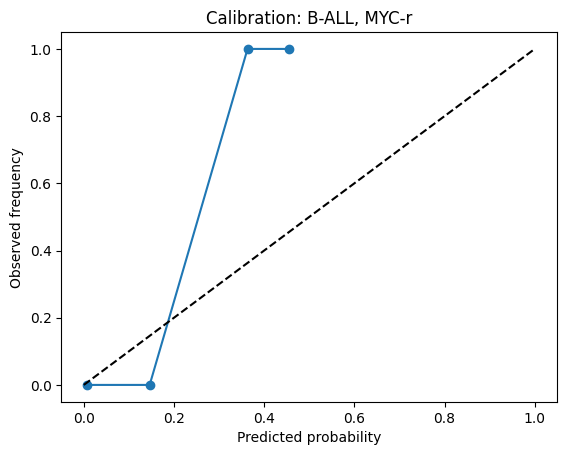

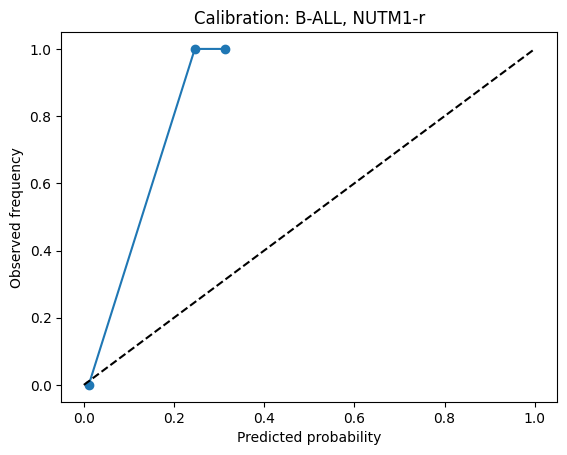

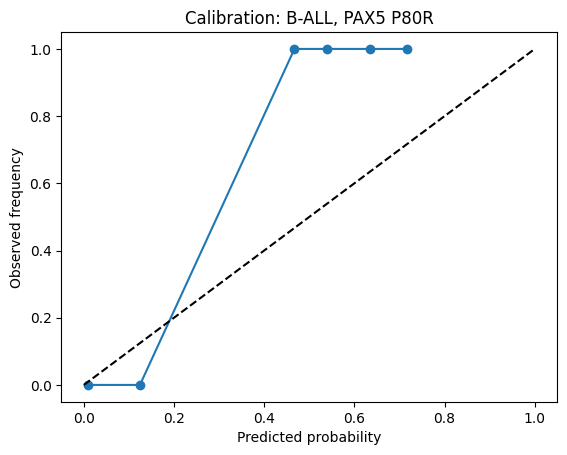

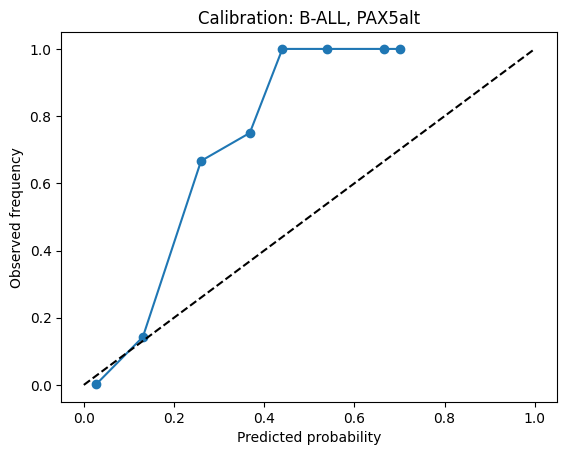

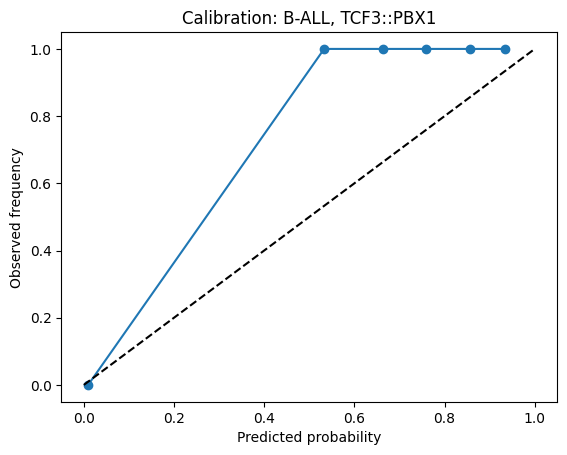

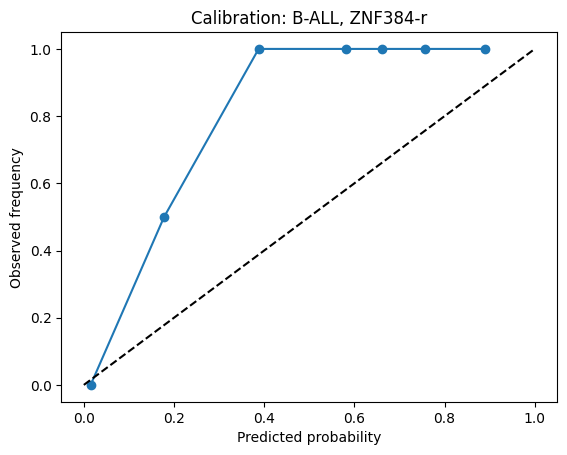

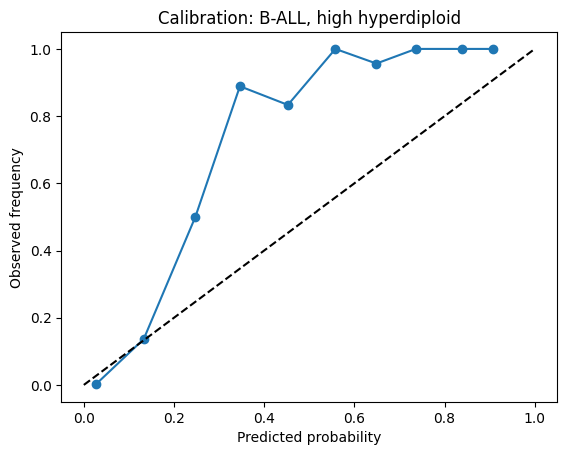

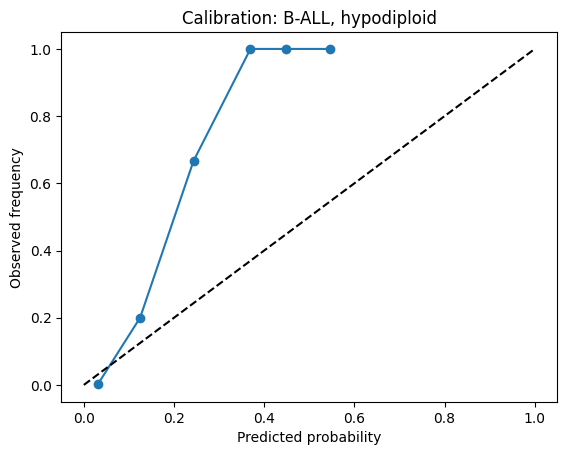

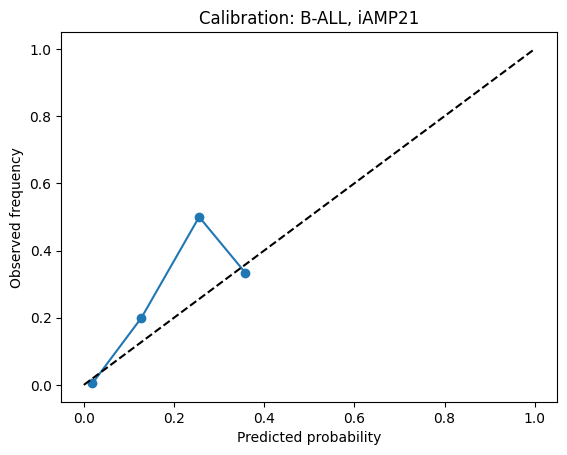

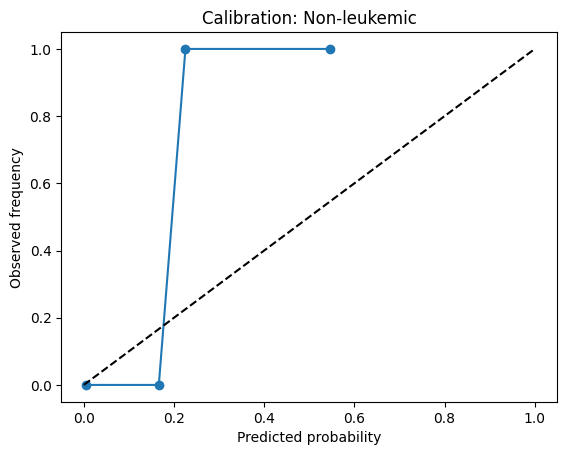

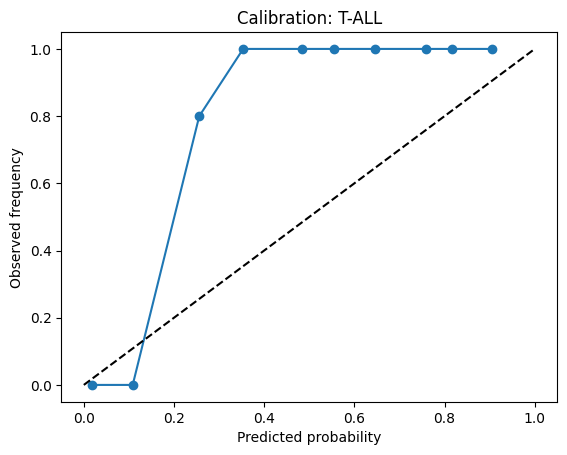

({'accuracy': 0.9279835390946503,
  'macro_f1': 0.9216482610997694,
  'micro_f1': 0.9279835390946503,
  'weighted_f1': 0.9248009222251246,
  'mcc': 0.9211552957959522,
  'cohen_kappa': 0.9208575855282441,
  'log_loss': 0.7077621669572269,
  'brier': np.float64(0.010049971056944688),
  'macro_auroc': 0.9968568720714869,
  'macro_auprc': np.float64(0.9559788701467722)},
                           precision    recall  f1-score     support     auroc  \
 AML, APL-PML::RARA         1.000000  1.000000  1.000000    1.000000  1.000000   
 AML, CBFA2T3::GLIS2        1.000000  1.000000  1.000000    1.000000  1.000000   
 AML, CBFB::MYH11           1.000000  1.000000  1.000000   10.000000  1.000000   
 AML, CEBPAalt              1.000000  0.666667  0.800000    3.000000  0.999310   
 AML, KMT2A-r               1.000000  0.937500  0.967742   16.000000  0.999335   
 AML, NPM1alt               0.800000  1.000000  0.888889    4.000000  0.997925   
 AML, NUP98-r               1.000000  1.000000  1.00000

In [19]:
from classifier_metrics import full_evaluation_report, classifier_level_metrics
# Get class names from model

class_names = rf_model.classes_.tolist()
class_to_idx = {cls: idx for idx, cls in enumerate(class_names)}
y_true_idx = np.array([class_to_idx.get(label, -1) for label in y_cal])
y_pred_idx = np.array([class_to_idx.get(label, -1) for label in y_cal_pred])

full_evaluation_report(y_true_idx, y_pred_idx, y_cal_proba, class_names)